# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [3]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"

# Si wine.csv no está en data/raw, se genera desde el dataset Wine de scikit-learn
# (178 muestras, 13 variables numéricas, 3 clases, columna objetivo "target").
if not DATA_PATH.exists():
    from sklearn.datasets import load_wine
    RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
    load_wine(as_frame=True).frame.to_csv(DATA_PATH, index=False)

df = pd.read_csv(DATA_PATH)
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [4]:
print("Forma:", df.shape)
print("\nTipos de dato:")
print(df.dtypes.value_counts())

nulls = df.isna().sum()
print("\nNulos totales:", int(nulls.sum()))
print(nulls[nulls > 0] if nulls.sum() else "Ninguna columna tiene nulos")

print("\nFilas duplicadas:", int(df.duplicated().sum()))

print("\nDistribución de target:")
print(pd.DataFrame({
    "n": df["target"].value_counts().sort_index(),
    "proporción": df["target"].value_counts(normalize=True).sort_index().round(3),
}))

df.describe().T[["mean", "std", "min", "max"]].round(2)

Forma: (178, 14)

Tipos de dato:
float64    13
int64       1
Name: count, dtype: int64

Nulos totales: 0
Ninguna columna tiene nulos

Filas duplicadas: 0

Distribución de target:
         n  proporción
target                
0       59       0.331
1       71       0.399
2       48       0.270


,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


**Conclusión de calidad:**

El archivo tiene **178 filas × 14 columnas**: 13 variables numéricas continuas (`float64`) y la columna `target` entera con 3 clases (59 / 71 / 48 muestras, es decir 33 % / 40 % / 27 %: desbalance leve). **No hay valores nulos ni filas duplicadas.**

Decisiones:
- No elimino ni imputo nada antes del split. Si hubiera nulos, la imputación (mediana) se hace dentro de los pipelines del Challenge 2, con estadísticos aprendidos solo en train, para evitar fuga de información.
- Split 80 / 20 **estratificado** por `target` con `random_state=42` → 142 filas de train y 36 de test, con las mismas proporciones de clase en ambos.
- El EDA se hace solo con `train_df`; `test.csv` queda guardado y sin explorar.

## 2. Split train/test

In [5]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["target"],
    random_state=RANDOM_STATE,
)

In [6]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

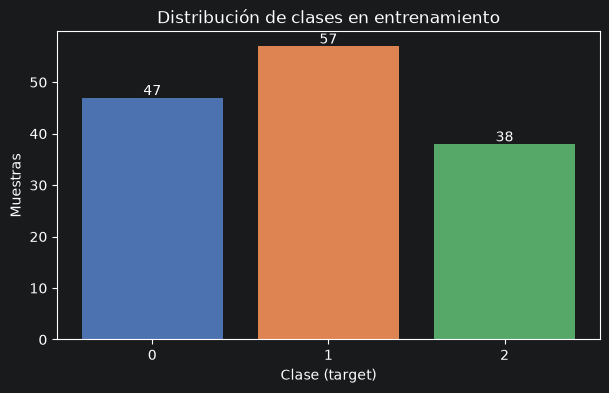

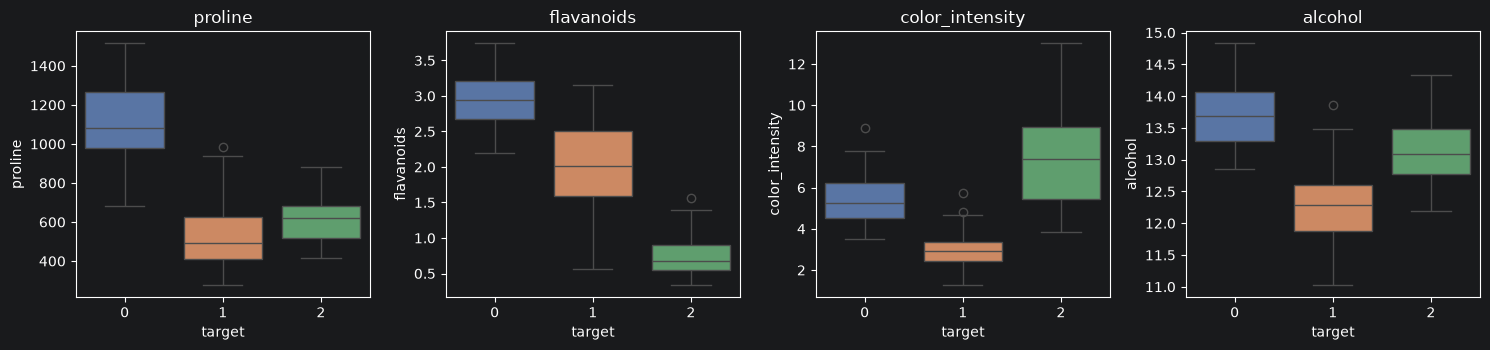

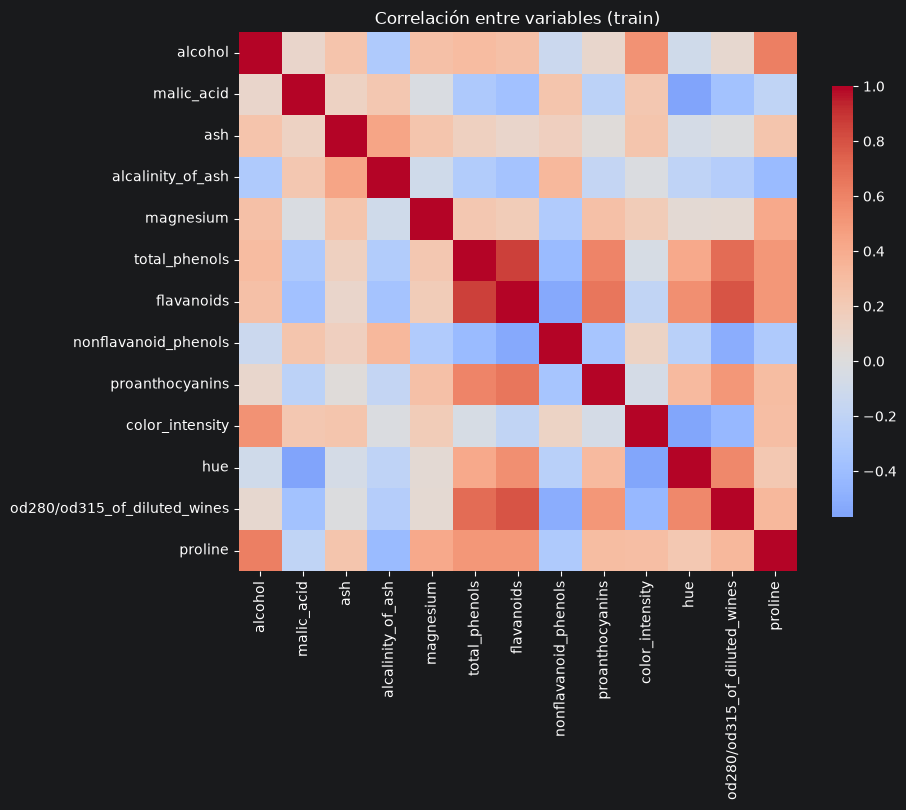

Pares de variables más correlacionados:
total_phenols  flavanoids                      0.86
flavanoids     od280/od315_of_diluted_wines    0.79
total_phenols  od280/od315_of_diluted_wines    0.69
flavanoids     proanthocyanins                 0.66
alcohol        proline                         0.62
dtype: float64

Escala de las variables (min - max):
                      min     max    rango
proline            278.00  1515.0  1237.00
magnesium           70.00   162.0    92.00
alcalinity_of_ash   10.60    30.0    19.40
color_intensity      1.28    13.0    11.72
malic_acid           0.74     5.8     5.06

Media por clase de variables discriminantes:
        proline  flavanoids  color_intensity  alcohol
target                                               
0       1092.34        2.93             5.48    13.70
1        526.25        2.01             2.98    12.28
2        622.89        0.78             7.39    13.11


In [7]:
# A partir de aquí SOLO se usa train_df. test_df no se toca.
feature_cols = [c for c in train_df.columns if c != "target"]

# 1) Distribución de clases
fig, ax = plt.subplots()
counts = train_df["target"].value_counts().sort_index()
ax.bar(counts.index.astype(str), counts.values, color=sns.color_palette("deep", len(counts)))
ax.set_xlabel("Clase (target)")
ax.set_ylabel("Muestras")
ax.set_title("Distribución de clases en entrenamiento")
for i, v in enumerate(counts.values):
    ax.text(i, v + 0.5, str(v), ha="center")
plt.show()

# 2) Boxplots de variables relevantes por clase
selected = ["proline", "flavanoids", "color_intensity", "alcohol"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, col in zip(axes, selected):
    sns.boxplot(data=train_df, x="target", y=col, hue="target", palette="deep", legend=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# 3) Matriz de correlación
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(train_df[feature_cols].corr(), cmap="coolwarm", center=0, ax=ax, cbar_kws={"shrink": .8})
ax.set_title("Correlación entre variables (train)")
plt.show()

# Cifras de apoyo para los hallazgos
corr = train_df[feature_cols].corr().abs()
pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack().sort_values(ascending=False).head(5).round(2))
print("Pares de variables más correlacionados:")
print(pairs)

print("\nEscala de las variables (min - max):")
rng = train_df[feature_cols].agg(["min", "max"]).T
print(rng.assign(rango=rng["max"] - rng["min"]).sort_values("rango", ascending=False).round(2).head(5))

print("\nMedia por clase de variables discriminantes:")
print(train_df.groupby("target")[["proline", "flavanoids", "color_intensity", "alcohol"]].mean().round(2))

**Hallazgos:**

1. **El problema es casi separable con pocas variables.** `proline` es alta en la clase 0 (media ≈ 1092 frente a ≈ 526 y ≈ 623), `flavanoids` es baja en la clase 2 (≈ 0.78 frente a ≈ 2.93 y ≈ 2.01) y `color_intensity` separa la clase 1 (≈ 2.98) de la clase 2 (≈ 7.39). Se espera buen desempeño incluso con modelos simples.
2. **Las variables tienen escalas muy distintas.** `proline` va de ~278 a ~1515, mientras que `hue` o `nonflavanoid_phenols` no pasan de 2. Los modelos basados en distancias (KNN) o en regularización (regresión logística) necesitan `StandardScaler`; los árboles no.
3. **Hay colinealidad entre variables.** `total_phenols`–`flavanoids` (|r| ≈ 0.86), `flavanoids`–`od280/od315` (≈ 0.79) y `alcohol`–`proline` (≈ 0.62). No daña la predicción, pero hace menos fiable interpretar coeficientes individuales y sugiere usar regularización.

## 4. Persistencia de datos y contrato

In [8]:
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_df.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

data_contract = {
    "target": "target",
    "features": [c for c in df.columns if c != "target"],
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
    "stratified": True,
    "n_rows_raw": int(len(df)),
    "n_rows_train": int(len(train_df)),
    "n_rows_test": int(len(test_df)),
    "classes": sorted(int(c) for c in df["target"].unique()),
}

(ARTIFACTS_DIR / "data_contract.json").write_text(
    json.dumps(data_contract, indent=2, ensure_ascii=False), encoding="utf-8"
)
print(json.dumps(data_contract, indent=2, ensure_ascii=False))

{
  "target": "target",
  "features": [
    "alcohol",
    "malic_acid",
    "ash",
    "alcalinity_of_ash",
    "magnesium",
    "total_phenols",
    "flavanoids",
    "nonflavanoid_phenols",
    "proanthocyanins",
    "color_intensity",
    "hue",
    "od280/od315_of_diluted_wines",
    "proline"
  ],
  "random_state": 42,
  "test_size": 0.2,
  "stratified": true,
  "n_rows_raw": 178,
  "n_rows_train": 142,
  "n_rows_test": 36,
  "classes": [
    0,
    1,
    2
  ]
}


In [9]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [x] Cargué el CSV desde `data/raw`.
- [x] Revisé calidad y distribución de la clase.
- [x] Realicé un split estratificado.
- [x] No exploré el conjunto de test.
- [x] Guardé los tres artefactos requeridos.